# Energy Price Forecasting with Random Forest Regression

By Albert Borchardt, 6871987, albert.borchardt@student.uni-tuebingen.de

In this notebook I implemented a Random Forest Regression model to predict hourly electricity prices for Germany (DE) for the next 24 hours.
Each day at 11:00, the model forecasted prices from 12:00 on the same day until 11:00 on the following day.

I used several datasets covering the period from January 1, 2019, to January 1, 2023:
- `Prices_Europe.csv`: historical electricity prices for DE
- `Predicted_Consumption.csv` and `Realised_Demand_Germany.csv`: electricity demand (forecast and actual)
- `Predicted_Supply.csv` and `Realised_Supply_Germany.csv`: electricity supply (forecast and actual)

The model was trained and evaluated using a rolling backtest approach: For each forecast day, I used all historical data available before 11:00 on that day to train the model. It then predicted hourly electricity prices for the upcoming 24-hour period—from 12:00 on the same day until 11:00 on the following day.


The chart below shows the historical price data, with weekly average prices and weekly price ranges (min/max). The extreme volatility during the 2022 backtest period (highlighted in blue) made forecasting particularly challenging.

![German Electricity Prices: Trend and Volatility](price_plot_final.png)

I evaluated model performance using RMSE (Root Mean Squared Error) and MAE (Mean Absolute Error) for each forecast day.

## Steps
1. Imports
2. Data Loading and Preparation
3. Feature engineering
4. Backtesting Strategy
5. Training & Prediction
6. Evaluation full year
7. Evaluation per day
8. Discussion

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import re
import os
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import holidays
import warnings
from tqdm.notebook import tqdm
from ipywidgets import interact, Dropdown
from IPython.display import Markdown, display
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (15, 7)
import matplotlib.dates as mdates 
from sklearn.cluster import KMeans
import datetime

### 2. Data Loading and Preparation

First, I needed to load and clean all the different data sources. My goal was to combine everything into a single master table that would serve as the foundation for the model.

* **Gathering Data Sources:** I worked with 7 datasets from the official German market platform SMARD and weather data (made available through the shared cloud environment provided by Professor Ludwig).
I chose these because I expected them to cover the fundamental drivers of electricity prices:
    * Historical Prices
    * Forecasted & Actual Consumption
    * Forecasted & Actual Generation
    * Regional Weather Data

* **Cleaning & Standardizing:** First, I cleaned each file individually. This meant standardizing all dates into a common `datetime` format, cleaning up number formats, and handling duplicate timestamps (which can occur during daylight saving time change) or renaming collumns (e.g. two different `Pumpspeicher` columns in different datasets) to distinguish between their demand and supply roles

* **Processing Weather Data:** The weather data required special handling. Since it came from many different locations across Germany, I used K-Means clustering on the station coordinates to group them into 4 distinct geographical regions. For each region, I then calculated the average temperature, solar radiation, and total wind speed for every hour (put simply: I wanted that the model e.g. learns that high wind in the north impacts the price differently than high sun in the south, without getting overwhelmed by too many data points).

* **Merging & Imputing:** Once I had prepared all the individual datasets, I merged them into one large master table called `df_all`. To handle small gaps that appeared after aligning the timestamps, I filled them by carrying over the last known value.

In [2]:
def parse_numbers(s):
    if isinstance(s, (int, float)):
        return s
    try:
        return float(str(s).replace('.', '').replace(',', '.'))
    except (ValueError, TypeError):
        return np.nan

print("Initiating data loading process...")

# 1) Prices -----------------------------------------------------------
try:
    df_price = pd.read_csv("Prices_Europe.csv", sep=";", encoding="utf-8")
    date_col = [c for c in df_price.columns if "date from" in c.lower()][0]
    df_price["datetime"] = pd.to_datetime(df_price[date_col], format="%d.%m.%y %H:%M", errors="coerce")
    df_price = (
        df_price.dropna(subset=["datetime"])
        .set_index("datetime")
        .rename(columns={"DE/LU [€/MWh]": "DE_Price"})
        .loc[lambda d: ~d.index.duplicated(keep="first")]
    )
    df_price["DE_Price"] = df_price["DE_Price"].apply(parse_numbers)
    df_price = df_price[["DE_Price"]]
    print(f"-> OK: Loaded Price data. Shape: {df_price.shape}")
except Exception as e:
    print(f"--> ERROR loading Prices: {e}")
    df_price = pd.DataFrame()

# 2) Predicted Supply -------------------------------------------------
try:
    df_supply_pred = pd.read_csv("Predicted_Supply.csv", sep=";", encoding="utf-8")
    date_col = [c for c in df_supply_pred.columns if "datum" in c.lower()][0]
    df_supply_pred["datetime"] = pd.to_datetime(df_supply_pred[date_col], format="%d.%m.%Y %H:%M", errors="coerce")
    df_supply_pred = (
        df_supply_pred.dropna(subset=["datetime"])
        .set_index("datetime")
        .drop(columns=[c for c in df_supply_pred.columns if "datum" in c.lower()])
        .loc[lambda d: ~d.index.duplicated(keep="first")]
        .applymap(parse_numbers)
        .add_suffix("_pred")
    )
    print(f"-> OK: Loaded Predicted Supply data. Shape: {df_supply_pred.shape}")
except Exception as e:
    print(f"--> ERROR loading Predicted Supply: {e}")
    df_supply_pred = pd.DataFrame()

# 3) Predicted Consumption -------------------------------------------
try:
    df_demand_pred = pd.read_csv("Predicted_Consumption.csv", sep=";", encoding="utf-8")
    date_col = [c for c in df_demand_pred.columns if "datum" in c.lower()][0]
    df_demand_pred["datetime"] = pd.to_datetime(df_demand_pred[date_col], format="%d.%m.%Y %H:%M", errors="coerce")
    df_demand_pred = (
        df_demand_pred.dropna(subset=["datetime"])
        .set_index("datetime")
        .drop(columns=[c for c in df_demand_pred.columns if "datum" in c.lower()])
        .loc[lambda d: ~d.index.duplicated(keep="first")]
        .applymap(parse_numbers)
        .add_suffix("_pred")
    )
    print(f"-> OK: Loaded Predicted Consumption data. Shape: {df_demand_pred.shape}")
except Exception as e:
    print(f"--> ERROR loading Predicted Consumption: {e}")
    df_demand_pred = pd.DataFrame()

# 4) Realised Demand --------------------------------------------------
try:
    df_demand_real = pd.read_csv("Realised_Demand_Germany.csv", sep=";", encoding="utf-8")
    pumpspeicher_col_list = [col for col in df_demand_real.columns if "Pumpspeicher" in col and "Netzlast" not in col]
    if len(pumpspeicher_col_list) == 1:
        original_col_name = pumpspeicher_col_list[0]
        df_demand_real.rename(columns={original_col_name: "Pumpspeicher_Demand [MWh]"}, inplace=True)
    
    date_col = [c for c in df_demand_real.columns if "datum von" in c.lower()][0]
    df_demand_real["datetime"] = pd.to_datetime(df_demand_real[date_col], format="%d.%m.%Y %H:%M", errors="coerce")
    df_demand_real = (
        df_demand_real.dropna(subset=["datetime"])
        .set_index("datetime")
        .drop(columns=[c for c in df_demand_real.columns if "datum" in c.lower()])
        .loc[lambda d: ~d.index.duplicated(keep="first")]
        .applymap(parse_numbers)
        .add_suffix("_real")
    )
    print(f"-> OK: Loaded Realised Demand data. Shape: {df_demand_real.shape}")
except Exception as e:
    print(f"--> ERROR loading Realised Demand: {e}")
    df_demand_real = pd.DataFrame()

# 5) Realised Supply --------------------------------------------------
try:
    df_supply_real = pd.read_csv("Realised_Supply_Germany.csv", sep=";", encoding="utf-8")
    pumpspeicher_col_list = [col for col in df_supply_real.columns if "Pumpspeicher" in col and "Netzlast" not in col]
    if len(pumpspeicher_col_list) == 1:
        original_col_name = pumpspeicher_col_list[0]
        df_supply_real.rename(columns={original_col_name: "Pumpspeicher_Supply [MWh]"}, inplace=True)
    
    date_col = [c for c in df_supply_real.columns if "datum von" in c.lower()][0]
    df_supply_real["datetime"] = pd.to_datetime(df_supply_real[date_col], format="%d.%m.%Y %H:%M", errors="coerce")
    df_supply_real = (
        df_supply_real.dropna(subset=["datetime"])
        .set_index("datetime")
        .drop(columns=[c for c in df_supply_real.columns if "datum" in c.lower()])
        .loc[lambda d: ~d.index.duplicated(keep="first")]
        .applymap(parse_numbers)
        .add_suffix("_real")
    )
    print(f"-> OK: Loaded Realised Supply data. Shape: {df_supply_real.shape}")
except Exception as e:
    print(f"--> ERROR loading Realised Supply: {e}")
    df_supply_real = pd.DataFrame()


# 6) Weather Data with K-Means Clustering -----------------------------
try:
    print("\n-> Loading and processing weather data with K-Means...")
    df_weather1 = pd.read_csv("Weather_Data_Germany.csv", delimiter=",")
    df_weather2 = pd.read_csv("Weather_Data_Germany_2022.csv", delimiter=",")
    df_weather = pd.concat([df_weather1, df_weather2], ignore_index=True)
    df_weather['datetime'] = pd.to_datetime(df_weather['time'], errors='coerce').dt.floor('H')
    
    locations = df_weather[['latitude', 'longitude']].drop_duplicates().reset_index(drop=True)
    
    NUM_CLUSTERS = 4
    kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=42, n_init=10)
    locations['cluster'] = kmeans.fit_predict(locations[['latitude', 'longitude']])
    
    df_weather = pd.merge(df_weather, locations, on=['latitude', 'longitude'])
    
    weather_vars = ['t2m', 'ssr', 'u10', 'v10']
    df_weather_clustered = df_weather.groupby(['datetime', 'cluster'])[weather_vars].mean().unstack('cluster')
    df_weather_clustered.columns = [f'{var}_cluster_{cluster}' for var, cluster in df_weather_clustered.columns]

    cols_to_drop = []
    for i in range(NUM_CLUSTERS):
        u_col = f'u10_cluster_{i}'
        v_col = f'v10_cluster_{i}'
        df_weather_clustered[f'wind_speed_cluster_{i}'] = np.sqrt(df_weather_clustered[u_col]**2 + df_weather_clustered[v_col]**2)
        cols_to_drop.extend([u_col, v_col])
    
    df_weather_clustered.drop(columns=cols_to_drop, inplace=True)
    print(f"-> OK: Created regional weather features (incl. wind speed). Shape: {df_weather_clustered.shape}")

except Exception as e:
    print(f"--> ERROR loading Weather data: {e}")
    df_weather_clustered = pd.DataFrame()

# Master-Index & Merge ----------------------------------
print("\nAligning all data sources to a common time index ...")
all_dfs = [df_price, df_supply_pred, df_demand_pred, df_demand_real, df_supply_real, df_weather_clustered]
all_dfs  = [df for df in all_dfs if not df.empty]

min_date = min(df.index.min() for df in all_dfs)
max_date = max(df.index.max() for df in all_dfs)
master_index = pd.date_range(min_date, max_date, freq="H")
print(f"Created master index from {min_date:%Y-%m-%d} to {max_date:%Y-%m-%d} ({len(master_index)} steps).")

df_all = pd.concat([df.reindex(master_index) for df in all_dfs], axis=1)
print(f"-> Merged data shape (before fill): {df_all.shape}")

df_all = df_all.ffill().bfill()
print(f"-> Final clean shape: {df_all.shape} | Remaining NaNs: {df_all.isna().sum().sum()}")


# =======================================================
# FINAL DATASET OVERVIEW
# =======================================================

# --- 1. Dataset Dimensions & Time Range ---
print("\n" + "="*55)
print("1. Dataset Dimensions & Time Range")
print("-"*55)
print(f"- Number of Rows (Hours):      {df_all.shape[0]:,}")
print(f"- Number of Columns (Features):  {df_all.shape[1]}")
print(f"- Time Period Start:             {df_all.index.min()}")
print(f"- Time Period End:               {df_all.index.max()}")
print("")

# --- 2. Key Statistics for Electricity Price (DE_Price) ---
print("="*55)
print("2. Key Statistics for Target Variable (DE_Price, €/MWh)")
print("-"*55)
price_stats_df = df_all['DE_Price'].describe().to_frame()
display(price_stats_df.style.format("{:,.2f}"))

# --- 3. Data Preview ---
print("\n" + "="*55)
print("3. Data Preview (First 5 Rows)")
print("-"*55)
display(df_all.head())

# Zeigt eine vollständige Liste aller Spaltennamen an
print("\nVollständige Spaltenliste in df_all:")
print(df_all.columns.tolist())

Initiating data loading process...
-> OK: Loaded Price data. Shape: (35060, 1)
-> OK: Loaded Predicted Supply data. Shape: (35060, 6)
-> OK: Loaded Predicted Consumption data. Shape: (35060, 2)
-> OK: Loaded Realised Demand data. Shape: (35060, 4)
-> OK: Loaded Realised Supply data. Shape: (35060, 12)

-> Loading and processing weather data with K-Means...
-> OK: Created regional weather features (incl. wind speed). Shape: (35064, 12)

Aligning all data sources to a common time index ...
Created master index from 2019-01-01 to 2022-12-31 (35064 steps).
-> Merged data shape (before fill): (35064, 37)
-> Final clean shape: (35064, 37) | Remaining NaNs: 0

1. Dataset Dimensions & Time Range
-------------------------------------------------------
- Number of Rows (Hours):      35,064
- Number of Columns (Features):  37
- Time Period Start:             2019-01-01 00:00:00
- Time Period End:               2022-12-31 23:00:00

2. Key Statistics for Target Variable (DE_Price, €/MWh)
----------

,DE_Price
count,"35,064.00"
mean,100.06
std,115.57
min,-90.01
25%,33.39
50%,49.69
75%,122.64
max,871.00



3. Data Preview (First 5 Rows)
-------------------------------------------------------


,DE_Price,Gesamt [MWh] Originalauflösungen_pred,Photovoltaik und Wind [MWh] Berechnete Auflösungen_pred,Wind Offshore [MWh] Berechnete Auflösungen_pred,Wind Onshore [MWh] Berechnete Auflösungen_pred,Photovoltaik [MWh] Berechnete Auflösungen_pred,Sonstige [MWh] Originalauflösungen_pred,Netzlast [MWh] Berechnete Auflösungen_pred,Residuallast [MWh] Berechnete Auflösungen_pred,Netzlast [MWh] Berechnete Auflösungen_real,...,t2m_cluster_2,t2m_cluster_3,ssr_cluster_0,ssr_cluster_1,ssr_cluster_2,ssr_cluster_3,wind_speed_cluster_0,wind_speed_cluster_1,wind_speed_cluster_2,wind_speed_cluster_3
2019-01-01 00:00:00,28.32,51071.0,23948.75,5069.00,18879.75,0.0,27122.25,43647.50,19698.75,43721.75,...,280.413096,275.560710,0.0,0.0,0.0,0.0,1.163418,6.124435,6.400179,2.366154
2019-01-01 01:00:00,10.07,51084.0,25668.75,5042.25,20626.50,0.0,25415.25,41692.50,16023.75,42069.00,...,280.402794,275.641786,0.0,0.0,0.0,0.0,1.206180,6.466388,6.800365,2.497365
2019-01-01 02:00:00,-4.08,51513.0,27384.00,5028.50,22355.50,0.0,24129.00,40587.50,13203.50,40508.00,...,280.299756,275.647539,0.0,0.0,0.0,0.0,1.331991,6.830062,7.188266,2.642643
2019-01-01 03:00:00,-9.91,52693.0,29010.25,4977.75,24032.50,0.0,23682.75,40308.25,11298.00,39682.50,...,280.314311,275.614046,0.0,0.0,0.0,0.0,1.543638,7.250436,7.522031,2.932131
2019-01-01 04:00:00,-7.41,53666.0,30359.25,4907.25,25452.00,0.0,23306.75,40659.50,10300.25,39437.50,...,280.365073,275.580074,0.0,0.0,0.0,0.0,1.920866,7.709684,7.551972,3.260393



Vollständige Spaltenliste in df_all:
['DE_Price', 'Gesamt [MWh] Originalauflösungen_pred', 'Photovoltaik und Wind [MWh] Berechnete Auflösungen_pred', 'Wind Offshore [MWh] Berechnete Auflösungen_pred', 'Wind Onshore [MWh] Berechnete Auflösungen_pred', 'Photovoltaik [MWh] Berechnete Auflösungen_pred', 'Sonstige [MWh] Originalauflösungen_pred', 'Netzlast [MWh] Berechnete Auflösungen_pred', 'Residuallast [MWh] Berechnete Auflösungen_pred', 'Netzlast [MWh] Berechnete Auflösungen_real', 'Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen_real', 'Pumpspeicher_Demand [MWh]_real', 'Residuallast [MWh] Berechnete Auflösungen_real', 'Biomasse [MWh] Berechnete Auflösungen_real', 'Wasserkraft [MWh] Berechnete Auflösungen_real', 'Wind Offshore [MWh] Berechnete Auflösungen_real', 'Wind Onshore [MWh] Berechnete Auflösungen_real', 'Photovoltaik [MWh] Berechnete Auflösungen_real', 'Sonstige Erneuerbare [MWh] Berechnete Auflösungen_real', 'Kernenergie [MWh] Berechnete Auflösungen_real', 'Braunkohle

<details>
<summary>
<font size="+1"><b>► Click to see the full list of Raw Data Columns</b></font>
</summary>

| Column | Description |
| :--- | :--- |
| **DE_Price** | Actual hourly electricity price (€/MWh) for Germany. |
| **Gesamt [MWh] Originalauflösungen_pred** | Total predicted generation across all sources (MWh). |
| **Photovoltaik und Wind [MWh] Berechnete Auflösungen_pred** | Predicted combined photovoltaic + wind generation (MWh). |
| **Wind Offshore [MWh] Berechnete Auflösungen_pred** | Predicted offshore wind generation (MWh). |
| **Wind Onshore [MWh] Berechnete Auflösungen_pred** | Predicted onshore wind generation (MWh). |
| **Photovoltaik [MWh] Berechnete Auflösungen_pred** | Predicted photovoltaic generation (MWh). |
| **Sonstige [MWh] Originalauflösungen_pred** | Predicted generation from other sources (MWh). |
| **Netzlast [MWh] Berechnete Auflösungen_pred** | Predicted grid load (consumption) (MWh). |
| **Residuallast [MWh] Berechnete Auflösungen_pred**| Predicted residual load (consumption minus renewables) (MWh). |
| **Netzlast [MWh] Berechnete Auflösungen_real** | Actual grid load (consumption) (MWh). |
| **Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen_real** | Actual grid load including pumped storage (MWh). |
| **Pumpspeicher_Demand [MWh]_real** | Actual electricity CONSUMPTION by pumped-storage (MWh) for pumping water uphill. |
| **Pumpspeicher_Supply [MWh]_real** | Actual electricity GENERATION by pumped-storage (MWh) from releasing water. |
| **Residuallast [MWh] Berechnete Auflösungen_real** | Actual residual load (MWh). |
| **Biomasse [MWh] Berechnete Auflösungen_real** | Actual biomass generation (MWh). |
| **Wasserkraft [MWh] Berechnete Auflösungen_real** | Actual hydropower generation (MWh). |
| **Wind Offshore [MWh] Berechnete Auflösungen_real** | Actual offshore wind generation (MWh). |
| **Wind Onshore [MWh] Berechnete Auflösungen_real** | Actual onshore wind generation (MWh). |
| **Photovoltaik [MWh] Berechnete Auflösungen_real** | Actual photovoltaic generation (MWh). |
| **Sonstige Erneuerbare [MWh] Berechnete Auflösungen_real** | Actual other renewable generation (MWh). |
| **Kernenergie [MWh] Berechnete Auflösungen_real** | Actual nuclear generation (MWh). |
| **Braunkohle [MWh] Berechnete Auflösungen_real** | Actual lignite (brown coal) generation (MWh). |
| **Steinkohle [MWh] Berechnete Auflösungen_real** | Actual hard-coal generation (MWh). |
| **Erdgas [MWh] Berechnete Auflösungen_real** | Actual natural-gas generation (MWh). |
| **Sonstige Konventionelle [MWh] Berechnete Auflösungen_real**| Actual other conventional generation (MWh). |
| **t2m_cluster_[0-3]** | Mean 2m air temperature (°C) for one of the 4 geographical clusters found by K-Means. |
| **ssr_cluster_[0-3]** | Mean surface solar radiation (MJ/m²) for one of the 4 geographical clusters. |
| **wind_speed_cluster_[0-3]** | Mean 10m wind speed (m/s), calculated from u10/v10 components, for one of the 4 clusters. |

</details>

### 3. Feature Engineering

After cleaning the data, I moved on to the most important part: feature engineering. Since Random Forests handle high-dimensional input well and automatically focus on the most relevant variables, I added a great variety of features to give the model maximum context for learning price dynamics.

* **Kept Raw Data:** I kept all the original columns from the combined dataset to give the model a snapshot of the current situation (e.g., the latest grid load forecast).

* **Added Time Features:** I pulled out time-based features like the hour and day of the week. To handle their cyclical nature, I also converted them into `sin/cos` pairs (to help the model understand that time repeats, for example, that hour 23 is close to hour 0, just like on a clock)

* **Created Lag / Rolling Features:** I generated a large number of features from the recent past, including lags (e.g., price 24 hours ago) and rolling statistics (average & std dev). I did this for the price itself and for other key drivers to give the model a sense of recent trends and volatility.

* **Calculated Forecast Errors:** I also calculated the error from past official forecasts (e.g., for demand). The idea was that by seeing past errors, the model could learn to correct for them.

* **Added a Holiday Flag:** I added a simple flag for German public holidays, since consumption is very different on those days.


Starting feature engineering process...
-> OK: Created time-based features.
-> OK: Created price lag/rolling features.
-> OK: Created holiday feature.
-> OK: Created forecast-error features.
-> OK: Created lag/rolling features for exogenous variables (including weather).
-> OK: Created 24 target columns.

Shape before dropna: (35064, 173)
Shape after  dropna: (34872, 173)


### Feature-Set Overview

| Category | # Columns |
|---|---|
| Raw data columns | **37** |
| Time features | **9** |
| Lag / rolling | **101** |
| Forecast-error | **10** |

**Total unique feature columns:** **149**

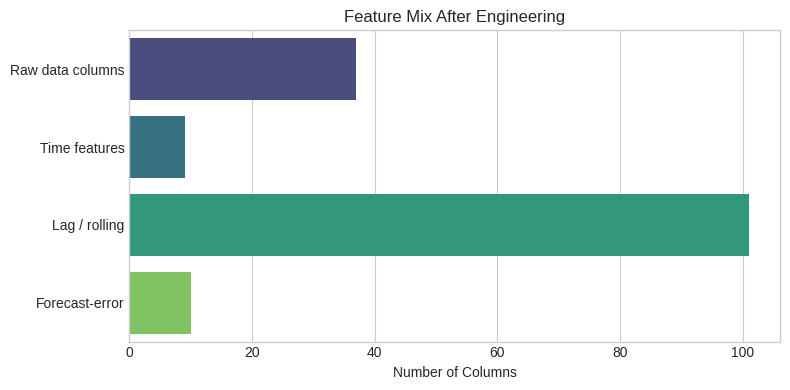

In [3]:
print("Starting feature engineering process...")

NUM_TARGET_HOURS  = 24
SHIFT_START_HOURS = 1
df_feat = df_all.copy()

# --- 1) Time-based features  ---------------------------
df_feat["hour_of_t"]      = df_feat.index.hour
df_feat["dayofweek_of_t"] = df_feat.index.dayofweek
df_feat["month_of_t"]     = df_feat.index.month
df_feat["year_of_t"]      = df_feat.index.year
df_feat["hour_of_t_sin"]  = np.sin(2*np.pi*df_feat["hour_of_t"]/24)
df_feat["hour_of_t_cos"]  = np.cos(2*np.pi*df_feat["hour_of_t"]/24)
df_feat["dayofweek_of_t_sin"] = np.sin(2*np.pi*df_feat["dayofweek_of_t"]/7)
df_feat["dayofweek_of_t_cos"] = np.cos(2*np.pi*df_feat["dayofweek_of_t"]/7)
print("-> OK: Created time-based features.")

# --- 2) Price lags / rolling --------------------------
for lag in [1, 2, 24, 48, 168]:
    df_feat[f"DE_Price_lag_{lag}h"] = df_feat["DE_Price"].shift(lag)
for win in [6, 12, 24, 168]:
    df_feat[f"DE_Price_roll_mean_{win}h"] = df_feat["DE_Price"].shift(1).rolling(win).mean()
    df_feat[f"DE_Price_roll_std_{win}h"]  = df_feat["DE_Price"].shift(1).rolling(win).std()
print("-> OK: Created price lag/rolling features.")

# --- 3) Holiday ---------------------------------
de_hdays = holidays.Germany(years=range(df_feat.index.year.min(), df_feat.index.year.max()+1))
df_feat["is_holiday_at_t"] = df_feat.index.to_series().map(
    lambda d: d.date() in de_hdays).astype(int)
print("-> OK: Created holiday feature.")

# --- 4) Forecast-error features -----------------------
pred_demand = "Netzlast [MWh] Berechnete Auflösungen_pred"
real_demand = "Netzlast [MWh] Berechnete Auflösungen_real"
pred_wind   = "Wind Onshore [MWh] Berechnete Auflösungen_pred"
real_wind   = "Wind Onshore [MWh] Berechnete Auflösungen_real"

if {pred_demand, real_demand}.issubset(df_feat.columns):
    df_feat["demand_forecast_error"] = df_feat[real_demand] - df_feat[pred_demand]
    for lag in [24, 48, 168]:
        df_feat[f"demand_error_lag_{lag}h"] = df_feat["demand_forecast_error"].shift(lag)
    for win in [24, 168]:
        df_feat[f"demand_error_roll_mean_{win}h"] = (
            df_feat["demand_forecast_error"].shift(1).rolling(win).mean()
        )
if {pred_wind, real_wind}.issubset(df_feat.columns):
    df_feat["wind_forecast_error"] = df_feat[real_wind] - df_feat[pred_wind]
    for lag in [24, 48, 168]:
        df_feat[f"wind_error_lag_{lag}h"] = df_feat["wind_forecast_error"].shift(lag)
print("-> OK: Created forecast-error features.")


# --- 5) Lags / rolling for other variables -------
weather_cluster_cols = [col for col in df_feat.columns if 'cluster' in col]
cols_to_lag = [pred_demand, real_demand, pred_wind, real_wind] + weather_cluster_cols
for col in cols_to_lag:
    if col in df_feat.columns:
        for lag in [24, 48, 168]:
            df_feat[f"{col}_lag_{lag}h"] = df_feat[col].shift(lag)
        for win in [24, 168]:
            df_feat[f"{col}_roll_mean_{win}h"] = df_feat[col].shift(1).rolling(win).mean()
print("-> OK: Created lag/rolling features for exogenous variables (including weather).")

# --- 6) Target columns --------------------------------
target_cols = []
for i in range(NUM_TARGET_HOURS):
    k  = SHIFT_START_HOURS + i
    tg = f"DE_target_h{i+1}"
    df_feat[tg] = df_feat["DE_Price"].shift(-k)
    target_cols.append(tg)
print("-> OK: Created 24 target columns.")

# --- 7) Drop NaNs -------------------------------------
print(f"\nShape before dropna: {df_feat.shape}")
df_feat.dropna(inplace=True)
print(f"Shape after  dropna: {df_feat.shape}")

# --- 8) Feature-Set Summary -----------------------------------------
feature_cols = [c for c in df_feat.columns if not c.startswith('DE_target')]
cat_counts = {
    "Raw data columns" : len([c for c in feature_cols if c in df_all.columns]),
    "Time features"    : len([c for c in feature_cols if any(t in c for t in ['_t','holiday'])]),
    "Lag / rolling"    : len([c for c in feature_cols if '_lag_' in c or '_roll_' in c]),
    "Forecast-error"   : len([c for c in feature_cols if 'error' in c])
}
md = "### Feature-Set Overview\n\n| Category | # Columns |\n|---|---|\n"
for k, v in cat_counts.items():
    md += f"| {k} | **{v}** |\n"
md += f"\n**Total unique feature columns:** **{len(feature_cols)}**"
display(Markdown(md))

plt.figure(figsize=(8, 4))
sns.barplot(x=list(cat_counts.values()), y=list(cat_counts.keys()), palette="viridis", orient='h')
plt.title("Feature Mix After Engineering")
plt.xlabel("Number of Columns")
plt.ylabel("")
plt.tight_layout()
plt.show()

<details>
<summary>
<font size="+1"><b>► Click to see Examples of Engineered Features</b></font>
</summary>


| Feature Name | Description |
| :--- | :--- |
| **`hour_of_t_cos`** | The cosine of the hour, helping the model understand the 24-hour daily cycle. |
| **`is_holiday_at_t`** | A binary flag (1 or 0) that indicates if the current day is a public holiday in Germany. |
| **`DE_Price_lag_24h`** | The electricity price from exactly 24 hours ago |
| **`DE_Price_roll_mean_6h`** | The average electricity price over the last 6 hours |
| **`DE_Price_roll_std_24h`** | The standard deviation of the price over the last 24 hours |
| **`Residuallast [MWh] Berechnete Auflösungen_pred`**| The predicted residual load: how much demand needs to be covered by conventional power plants. |
| **`wind_speed_cluster_2`** | The calculated wind speed for one of the 4 geographical regions in Germany. |
| **`demand_forecast_error`** | The difference between the predicted and the actual grid load from the past. |
| **`Netzlast [MWh] Berechnete Auflösungen_pred_lag_24h`** | The value of the grid load forecast from 24 hours ago. |

</details>

### 4. Backtesting Strategy

Here I set up a backtest to simulate how the model would perform in a real-world scenario.

* **What:** I selected the entire year of 2022 as the evaluation period and identified every day at 11:00 AM as a starting point for a new forecast.
* **Why:** This day-by-day simulation was a more rigorous and realistic method for evaluating a time series model than a simple, static train/test split (which led to poor results in my initial tests, as performance degraded the further the forecast period was from the training data).
* **How:** A list of these 11:00 AM timestamps was created. The model would later loop through this list, re-training on all available past data and forecasting the next 24 hours for each point in time.

In [4]:
backtest_start_date = '2022-01-01'
backtest_end_date = '2022-12-31'

date_range_df = df_feat[backtest_start_date:backtest_end_date]
prediction_origins_for_backtest = date_range_df[date_range_df.index.hour == 11].index

if len(prediction_origins_for_backtest) == 0:
    raise ValueError("No valid prediction origins found in the specified backtest period.")

num_days = len(prediction_origins_for_backtest)
start_date_log = prediction_origins_for_backtest.min().strftime('%Y-%m-%d')
end_date_log = prediction_origins_for_backtest.max().strftime('%Y-%m-%d')        

print(f"Backtest configured: {num_days} days from {start_date_log} to {end_date_log} will be selected as the prediction period.")

Backtest configured: 364 days from 2022-01-01 to 2022-12-30 will be selected as the prediction period.


### 5. Training & Prediction

Now I executed the backtesting strategy. I looped through each day of the evaluation period, simulating the process of training a new model and generating a 24-hour forecast.

* **The Backtesting Loop:** I iterated through each prediction origin (every 11:00 AM in 2022). For each day, I performed the following steps:
   1. **Dynamic Data Split:** I split the data into a training set (all hours *before* the current 11:00 AM origin) and a test set (the single row *at* 11:00 AM).
   2. **Target-Time Feature Engineering:** In addition to the global features created beforehand (e.g. lags, rolling statistics, weather data), I added a few time-specific features during the loop to describe the prediction target itself—such as the target hour, day of week, and a holiday flag.
   3. **Model Training:** I used a Direct Multi-Step forecast strategy. Instead of training one model, I trained 24 independent Random Forest models, one for each forecast horizon (e.g. `h+1`, `h+2`, ..., `h+24`).
      * **Random Forest:** An ensemble method that built multiple decision trees. For regression, the prediction was the average of all trees.
      * **Model Configuration:** I configured the models with these hyperparameters to balance performance and prevent overfitting:
        - `n_estimators=100`: Number of trees per forest
        - `max_depth=15`: Maximum tree depth
        - `min_samples_split=20`: Minimum samples required to split a node
        - `min_samples_leaf=8`: Minimum samples required in a leaf node
        - `max_features='sqrt'`: Random subset of features considered at each split
        - `n_jobs=-1`: Used all CPU cores for parallel training
   4. **Prediction:** Each of the 24 specialist models made its prediction for the corresponding hour, forming a complete 24-hour forecast.
   5. **Evaluation & Storage:** I compared predictions to actual values, calculated daily `RMSE` and `MAE`, and stored the results for later analysis.

In [5]:
daily_metrics = [] 
all_forecasts = {} 


def is_target_holiday(target_date, holiday_dict):
    return 1 if pd.to_datetime(target_date).date() in holiday_dict else 0

min_year_feat = df_feat.index.year.min()
max_year_feat = df_feat.index.year.max() + 1
all_german_holidays = holidays.Germany(years=range(min_year_feat, max_year_feat))

for forecast_origin in tqdm(prediction_origins_for_backtest, desc="Backtesting Progress"):
    
    current_day_str = forecast_origin.strftime('%Y-%m-%d')
   
    print(f"\n--- Processing Forecast for: {current_day_str} ---")
    
    # 1. Split Data for current day
    train_df = df_feat[df_feat.index < forecast_origin].copy()
    test_df = df_feat.loc[[forecast_origin]].copy()
    print(f"1. Data Split: Training data contains {len(train_df):,} rows.")

    feature_columns = [col for col in df_feat.columns if not col.startswith('DE_target')]
    X_train = train_df[feature_columns]
    Y_train = train_df[target_cols]
    X_test = test_df[feature_columns]
    Y_test = test_df[target_cols]

    # 2. Train 24 Models for the current day
    print("2. Training Models: Starting to train 24 models...")
    models = {}
    for i, target_col in enumerate(target_cols):
        k_offset = SHIFT_START_HOURS + i
        y_train_h = Y_train[target_col]
        X_train_h = X_train.copy()
        
        # Create features about the target time itself
        target_datetime = X_train_h.index + pd.Timedelta(hours=k_offset)
        X_train_h['target_hour_sin'] = np.sin(2 * np.pi * target_datetime.hour / 24)
        X_train_h['target_hour_cos'] = np.cos(2 * np.pi * target_datetime.hour / 24)
        X_train_h['target_dayofweek_sin'] = np.sin(2 * np.pi * target_datetime.dayofweek / 7)
        X_train_h['target_dayofweek_cos'] = np.cos(2 * np.pi * target_datetime.dayofweek / 7)
        X_train_h['target_is_holiday'] = [is_target_holiday(ts, all_german_holidays) for ts in target_datetime]

        # Define and fit the model
        rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, max_depth=15, min_samples_split=20, min_samples_leaf=8, max_features='sqrt')
        rf_model.fit(X_train_h, y_train_h)
        models[target_col] = (rf_model, X_train_h.columns)
    print("   -> OK: All 24 models trained.")

    # 3. Make Predictions for the current day
    print("3. Making Predictions for the 24-hour block...")
    predictions_all_horizons = {}
    for i, target_col in enumerate(target_cols):
        model, train_cols = models[target_col]
        k_offset = SHIFT_START_HOURS + i
        X_test_h = X_test.copy()
        
        # Create the same target-time features for the test set
        target_dt = X_test_h.index + pd.Timedelta(hours=k_offset)
        X_test_h['target_hour_sin'] = np.sin(2 * np.pi * target_dt.hour / 24)
        X_test_h['target_hour_cos'] = np.cos(2 * np.pi * target_dt.hour / 24)
        X_test_h['target_dayofweek_sin'] = np.sin(2 * np.pi * target_dt.dayofweek / 7)
        X_test_h['target_dayofweek_cos'] = np.cos(2 * np.pi * target_dt.dayofweek / 7)
        X_test_h['target_is_holiday'] = [is_target_holiday(ts, all_german_holidays) for ts in target_dt]
        
        # Ensure test columns match training columns
        X_test_h = X_test_h.reindex(columns=train_cols, fill_value=0)
        
        y_pred = model.predict(X_test_h)
        predictions_all_horizons[target_col] = y_pred

    predictions_df = pd.DataFrame(predictions_all_horizons, index=X_test.index)
    print("   -> OK: Predictions made.")

    # 4. Evaluate and Store Results
    y_true_block = Y_test.iloc[0].values
    y_pred_block = predictions_df.iloc[0].values
    
    rmse = np.sqrt(mean_squared_error(y_true_block, y_pred_block))
    mae = mean_absolute_error(y_true_block, y_pred_block)
    
    daily_metrics.append({'date': forecast_origin, 'rmse': rmse, 'mae': mae})
    all_forecasts[forecast_origin] = {'true': y_true_block, 'pred': y_pred_block}
    print(f"4. Evaluation: Daily RMSE={rmse:.2f}, MAE={mae:.2f}. Results stored.")

print("\nBacktest complete.")

output_dir_data = "backtest_results"
os.makedirs(output_dir_data, exist_ok=True)

with open(os.path.join(output_dir_data, 'daily_metrics.pkl'), 'wb') as f:
    pickle.dump(daily_metrics, f)

with open(os.path.join(output_dir_data, 'all_forecasts.pkl'), 'wb') as f:
    pickle.dump(all_forecasts, f)

print(f"\nBacktest results saved to '{output_dir_data}' folder.")


Backtesting Progress:   0%|          | 0/364 [00:00<?, ?it/s]


--- Processing Forecast for: 2022-01-01 ---
1. Data Split: Training data contains 26,147 rows.
2. Training Models: Starting to train 24 models...
   -> OK: All 24 models trained.
3. Making Predictions for the 24-hour block...
   -> OK: Predictions made.
4. Evaluation: Daily RMSE=31.82, MAE=28.12. Results stored.

--- Processing Forecast for: 2022-01-02 ---
1. Data Split: Training data contains 26,171 rows.
2. Training Models: Starting to train 24 models...
   -> OK: All 24 models trained.
3. Making Predictions for the 24-hour block...
   -> OK: Predictions made.
4. Evaluation: Daily RMSE=30.41, MAE=24.67. Results stored.

--- Processing Forecast for: 2022-01-03 ---
1. Data Split: Training data contains 26,195 rows.
2. Training Models: Starting to train 24 models...
   -> OK: All 24 models trained.
3. Making Predictions for the 24-hour block...
   -> OK: Predictions made.
4. Evaluation: Daily RMSE=39.20, MAE=31.44. Results stored.

--- Processing Forecast for: 2022-01-04 ---
1. Data Sp

### 6. Evaluation full year

Loading backtest results from 'backtest_results'...
Results loaded successfully.

Average RMSE over period: 48.51 €/MWh
Average MAE over period:  39.96 €/MWh


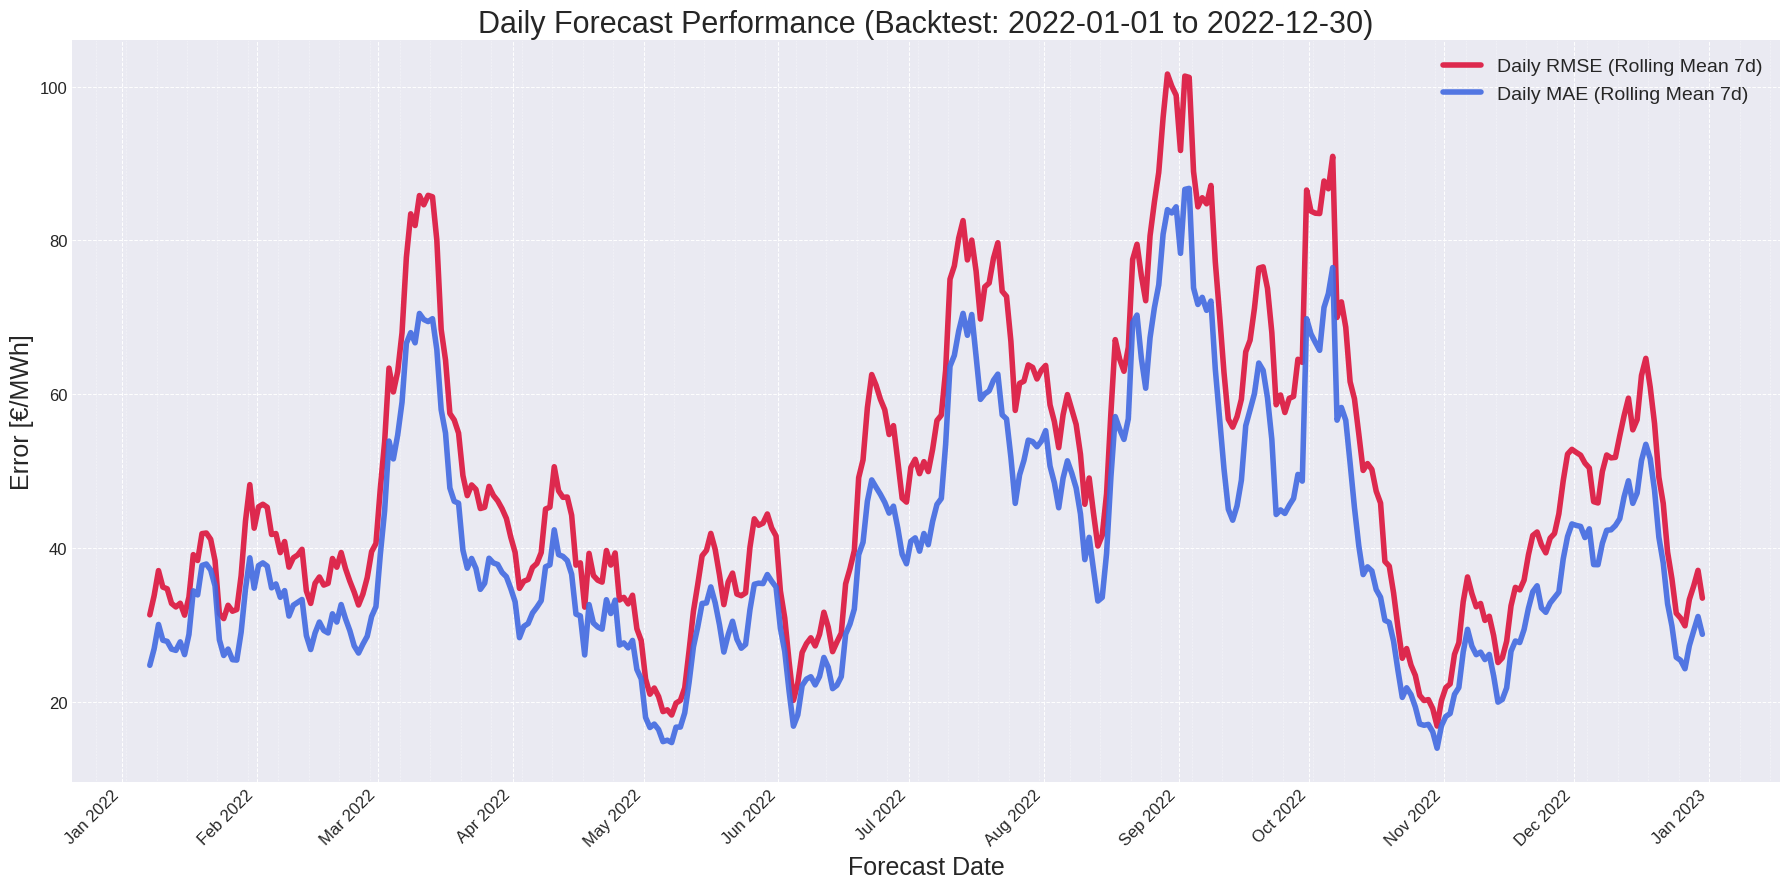

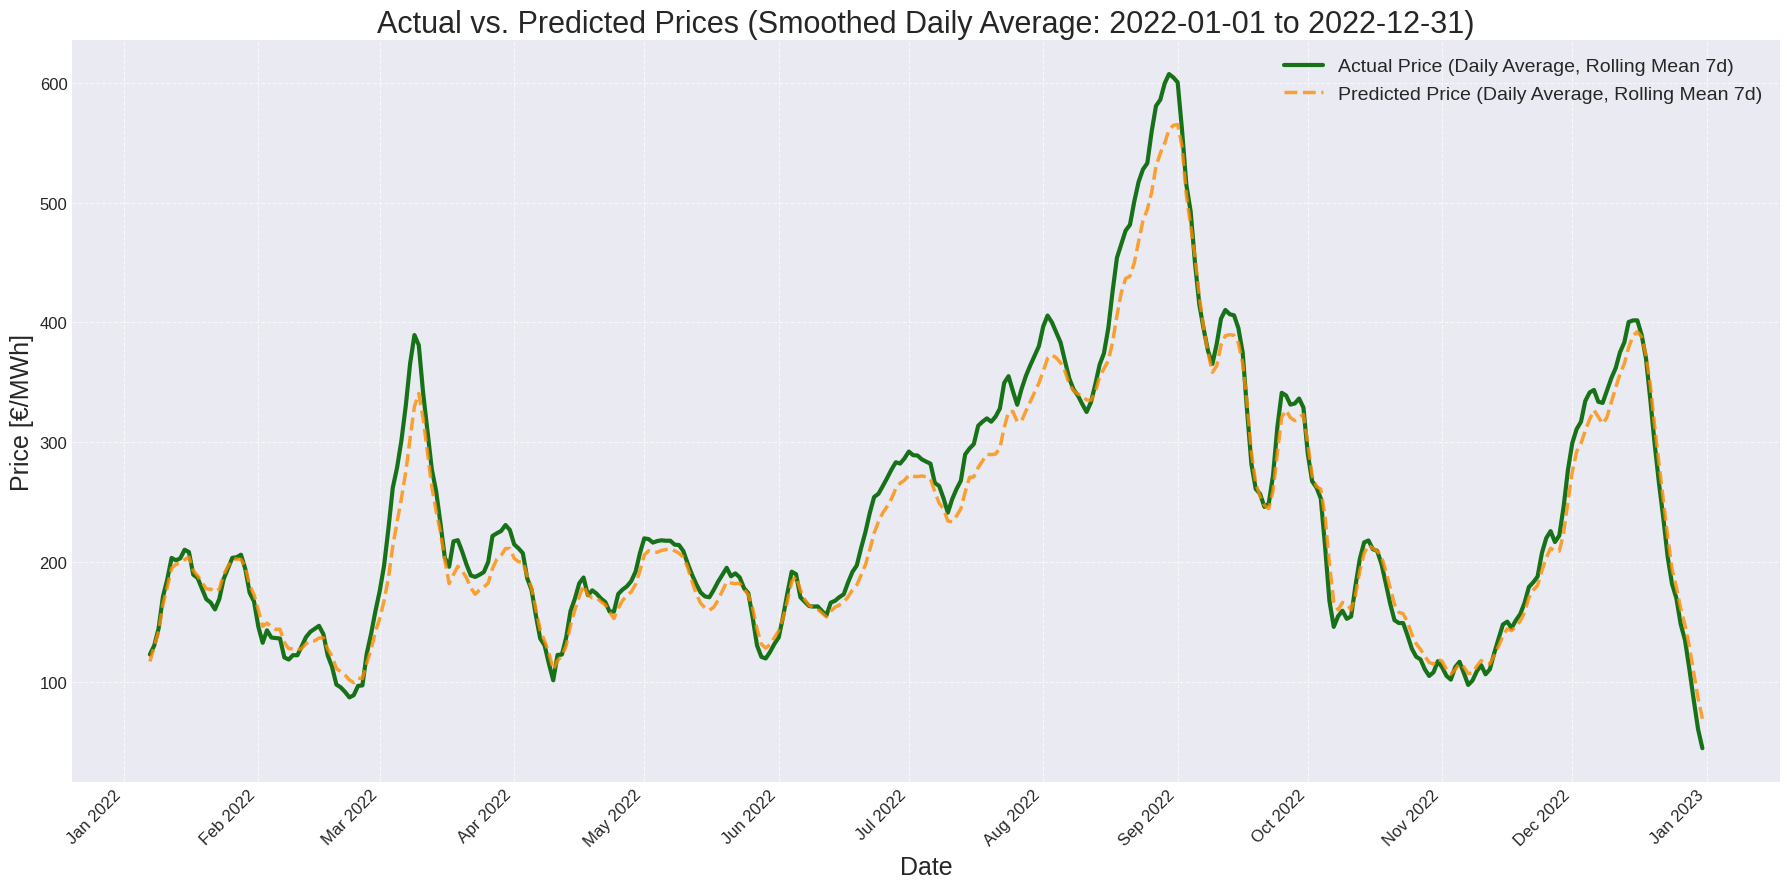

In [6]:
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (18, 9)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 14

output_dir_data = "backtest_results"
print(f"Loading backtest results from '{output_dir_data}'...")

try:
    with open(os.path.join(output_dir_data, 'daily_metrics.pkl'), 'rb') as f:
        daily_metrics = pickle.load(f)
    with open(os.path.join(output_dir_data, 'all_forecasts.pkl'), 'rb') as f:
        all_forecasts = pickle.load(f)
    print("Results loaded successfully.")
except FileNotFoundError:
    print(f"Error: Backtest results files not found in '{output_dir_data}'.")
    print("Please ensure the backtest (Cell 5) has been run and results saved.")
    daily_metrics = []
    all_forecasts = {}

results_df = pd.DataFrame(daily_metrics)

if results_df.empty:
    print("No results available for plotting daily performance.")
else:
    results_df = results_df.set_index('date')

    window_size_error = 7
    results_df['rmse_rolling_mean'] = results_df['rmse'].rolling(window=window_size_error).mean()
    results_df['mae_rolling_mean'] = results_df['mae'].rolling(window=window_size_error).mean()

    mean_rmse = results_df['rmse'].mean()
    mean_mae = results_df['mae'].mean()

    print(f"\nAverage RMSE over period: {mean_rmse:.2f} €/MWh")
    print(f"Average MAE over period:  {mean_mae:.2f} €/MWh")

    fig1, ax1 = plt.subplots(figsize=(18, 9))

    ax1.plot(results_df.index, results_df['rmse_rolling_mean'],
             label=f'Daily RMSE (Rolling Mean {window_size_error}d)',
             color='crimson', linewidth=4, alpha=0.9)
    ax1.plot(results_df.index, results_df['mae_rolling_mean'],
             label=f'Daily MAE (Rolling Mean {window_size_error}d)',
             color='royalblue', linewidth=4, alpha=0.9)

    ax1.set_title(f'Daily Forecast Performance (Backtest: {results_df.index.min().strftime("%Y-%m-%d")} to {results_df.index.max().strftime("%Y-%m-%d")})', fontsize=22)
    ax1.set_ylabel('Error [€/MWh]', fontsize=18)
    ax1.set_xlabel('Forecast Date', fontsize=18)
    ax1.legend()
    ax1.grid(True, which='major', linestyle='--', linewidth=0.7)
    ax1.grid(True, which='minor', linestyle=':', linewidth=0.4)

    ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax1.xaxis.set_minor_locator(mdates.DayLocator(interval=7))

    fig1.autofmt_xdate(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

if not all_forecasts:
    print("No forecast data available for plotting prices.")
else:
    true_values = []
    pred_values = []
    datetimes = []

    sorted_forecast_origins = sorted(all_forecasts.keys())

    for origin in sorted_forecast_origins:
        true_block = all_forecasts[origin]['true']
        pred_block = all_forecasts[origin]['pred']

        forecast_start_datetime = origin + pd.Timedelta(hours=SHIFT_START_HOURS)
        hourly_forecast_range = pd.date_range(start=forecast_start_datetime, periods=NUM_TARGET_HOURS, freq='H')

        true_values.extend(true_block)
        pred_values.extend(pred_block)
        datetimes.extend(hourly_forecast_range)

    ts_true = pd.Series(true_values, index=datetimes)
    ts_pred = pd.Series(pred_values, index=datetimes)

    ts_true = ts_true[~ts_true.index.duplicated(keep='first')]
    ts_pred = ts_pred[~ts_pred.index.duplicated(keep='first')]

    daily_true_avg = ts_true.resample('D').mean()
    daily_pred_avg = ts_pred.resample('D').mean()

    window_size_price = 7
    daily_true_avg_rolling = daily_true_avg.rolling(window=window_size_price).mean()
    daily_pred_avg_rolling = daily_pred_avg.rolling(window=window_size_price).mean()

    fig2, ax2 = plt.subplots(figsize=(18, 9))

    ax2.plot(daily_true_avg_rolling.index, daily_true_avg_rolling,
             label=f'Actual Price (Daily Average, Rolling Mean {window_size_price}d)',
             color='darkgreen', linewidth=3, alpha=0.9)
    ax2.plot(daily_pred_avg_rolling.index, daily_pred_avg_rolling,
             label=f'Predicted Price (Daily Average, Rolling Mean {window_size_price}d)',
             color='darkorange', linewidth=2.5, alpha=0.8, linestyle='--')

    ax2.set_title(f'Actual vs. Predicted Prices (Smoothed Daily Average: {ts_true.index.min().strftime("%Y-%m-%d")} to {ts_true.index.max().strftime("%Y-%m-%d")})', fontsize=22)
    ax2.set_ylabel('Price [€/MWh]', fontsize=18)
    ax2.set_xlabel('Date', fontsize=18)
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.7)

    ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax2.xaxis.set_minor_locator(mdates.DayLocator(interval=7))

    fig2.autofmt_xdate(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

- **Overall Error Levels**  
  - Average RMSE: 48.51 €/MWh
  - Average MAE:  39.96 €/MWh  

- **Error Trend (7-day Rolling Mean of RMSE/MAE)**  
  - Peaks in March, late July/August, September and October, matching major price surges.  
  - Lows in quiet periods (e.g. January, May-June. November–December).

- **Actual vs. Predicted Daily Averages (7-day Rolling Mean)**  
  - The model’s (smoothed predictions) track the true price trend quite closely throughout the year.  
  - During major price surges, the forecast tends to underestimate peaks by a small margin, but captures the overall rise and fall.  
  - In low-volatility phases, the two curves almost overlap

- **Combined Insights**  
  - **Volatility drives error**: every major price spike (no matter if up or down) corresponds to a jump in RMSE/MAE.  
  - Model tracks trend shifts well but underestimates extreme amplitudes.  

### 7. Evaluation per day

In [7]:
if not all_forecasts:
    print("No forecast data available to save plots.")
else:
    output_dir = "daily_forecast_plots"
    os.makedirs(output_dir, exist_ok=True)
    print(f"All plots will be saved in the folder: '{output_dir}/'")
    for day_to_plot, data in tqdm(all_forecasts.items(), desc="Saving Plots"):
        y_true = data['true']
        y_pred = data['pred']
        metrics = results_df.loc[day_to_plot]
        rmse = metrics['rmse']
        mae = metrics['mae']
        fig, ax = plt.subplots(figsize=(15, 8)) 
        forecast_datetime_index = [
            day_to_plot + pd.Timedelta(hours=SHIFT_START_HOURS + i)
            for i in range(NUM_TARGET_HOURS)
        ]
        ax.plot(forecast_datetime_index, y_true, label="Actual Price", color="navy", marker='o', linewidth=2)
        ax.plot(forecast_datetime_index, y_pred, label="Predicted Price", color="darkorange", marker='x', linewidth=2)
        title_date_str = pd.Timestamp(day_to_plot).strftime('%Y-%m-%d')
        ax.set_title(
            f"24-Hour Forecast for {title_date_str}\nRMSE: {rmse:.2f} €/MWh | MAE: {mae:.2f} €/MWh", 
            fontsize=16
        )
        ax.set_xlabel("Forecast Hour", fontsize=12)
        ax.set_ylabel("Price [€/MWh]", fontsize=12)
        plt.xticks(rotation=45, ha='right')
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.7)
        filename = f"forecast_{title_date_str}.png"
        filepath = os.path.join(output_dir, filename)
        plt.savefig(filepath, dpi=120, bbox_inches='tight')
        plt.close(fig)

    print(f"\nSuccessfully saved {len(all_forecasts)} plots to the '{output_dir}' folder.")

All plots will be saved in the folder: 'daily_forecast_plots/'


Saving Plots:   0%|          | 0/364 [00:00<?, ?it/s]


Successfully saved 364 plots to the 'daily_forecast_plots' folder.


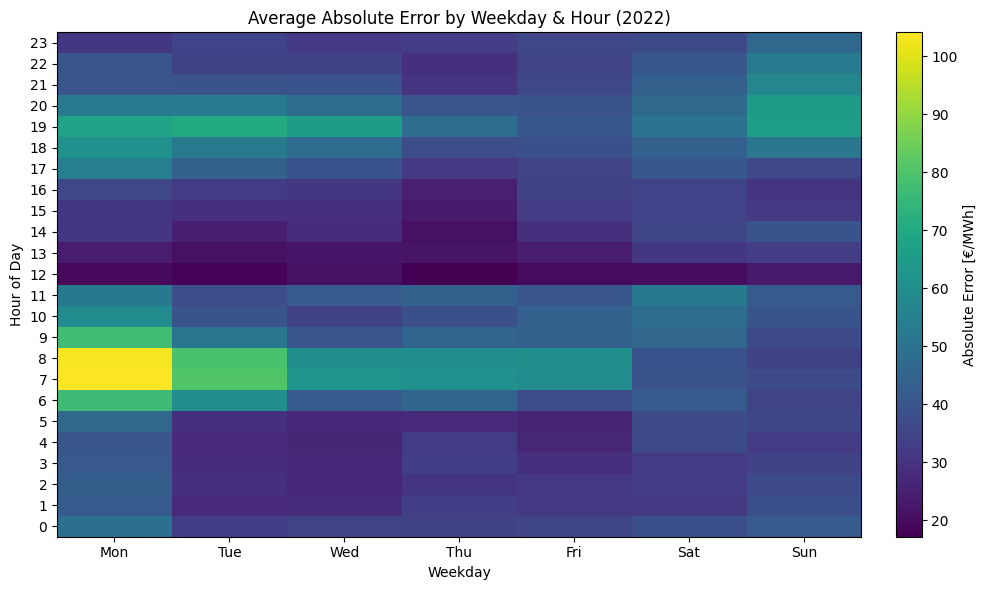

In [3]:
import pickle
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

with open("backtest_results/all_forecasts.pkl", "rb") as f:
    all_forecasts = pickle.load(f)

records = []
for origin, data in all_forecasts.items():
    true_vals = data['true']
    pred_vals = data['pred']
    for i, (t, p) in enumerate(zip(true_vals, pred_vals)):
        ts = origin + pd.Timedelta(hours=i+1)  
        records.append({"timestamp": ts, "error": abs(t - p)})

df_err = pd.DataFrame(records)
df_err['weekday'] = df_err['timestamp'].dt.weekday 
df_err['hour'] = df_err['timestamp'].dt.hour

weekday_hour = df_err.groupby(['hour', 'weekday'])['error'] \
                     .mean().unstack('weekday')

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(weekday_hour, origin='lower', aspect='auto', cmap='viridis')

ax.set_yticks(np.arange(24))
ax.set_yticklabels(np.arange(24))
ax.set_xticks(np.arange(7))
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_xlabel('Weekday')
ax.set_ylabel('Hour of Day')
ax.set_title('Average Absolute Error by Weekday & Hour (2022)')

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Absolute Error [€/MWh]')

plt.tight_layout()
plt.show()


- **Peak Errors**  
  - Weekday mornings at 07–08 h show the highest MAE (~100–110 €/MWh), especially on Monday.

- **Lowest Errors**  
  - Midday 11–13 h across all days (~15–25 €/MWh).

- **Evening & Night**  
  - Moderate error (~30–50 €/MWh) in 17–20 h and 00–05 h.

- **Weekends vs. Weekdays**  
  - Sat/Sun generally lower MAE (30–45 €/MWh) than weekdays.

- **Origin Proximity Effect**  
  - Hours near the forecast origin (11 h) have lower MAE.  
  - Errors increase for longer horizons, peaking at 07–08 h

- **Implication**  
  - Especially morning ramps (far from the forcast origin) and also a bit the evening transitions cause problems




Three representative days:

1. **Best Day (Lowest Error) – 2022-10-29**  
   The model followed the price curve very closely, both during the night and day so errors were small. This was a low-price day, with prices between 85 and 140 €/MWh.    
   ![2022-10-29 Forecast](daily_forecast_plots/forecast_2022-10-29.png)

2. **Worst Day (Highest Error) – 2022-08-28**  
   The model were partly off several €/MWh and missed e.g. a big price spike in the evening. Something like this would happened during a time with very high prices, here going above 700 €/MWh. 
   ![2022-08-28 Forecast](daily_forecast_plots/forecast_2022-08-28.png)

3. **Most Average Day – 2022-05-11**  
   The model got the general shape of the price curve right, but the values were sometimes a bit too high or too low. 
   ![2022-05-11 Forecast](daily_forecast_plots/forecast_2022-05-11.png)






### 8. Discussion

In [ ]:
fi_df = (
    pd.concat(
        [
            pd.Series(rf.feature_importances_, index=cols, name=horizon)
            for horizon, (rf, cols) in models.items()
        ],
        axis=1
    )
    .fillna(0)
)
fi_df["mean_importance"] = fi_df.mean(axis=1)
top_n = 30
(
    fi_df["mean_importance"]
    .nlargest(top_n)
    .iloc[::-1]
    .plot(kind="barh", figsize=(10, 6))
)
plt.title(f"Mittlere Feature-Importance über alle 24 Horizonte ({top_n})")
plt.xlabel("Mean Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Note: The code generated the plot shown in the report as 'feature_importance.png'.
# Since the plot disappeared after rerunning the notebook and recreating it would have 
# required retraining all models (which is time-consuming), the saved PNG was embedded instead.

### Strengths and Potential Use Cases

- The model performs robustly across a full year, even under volatile market conditions (at least regarding general directions and trends) and with the rolling backtest a real-world operational performance is simulated
- Low operational complexity, fast inference (if only one day should be predicted)
- Potential Use Cases (a few ideas):
    - Trading: Improve day-ahead trading (although I would not trust the model with all my money...yet :P)
    - Industrial Load Shifting: Help energy-intensive businesses shift production to low-price hours and reduce costs
    - Tariff Design: Support energy providers in creating e.g. time-based electricity tariffs for their customers


### Limitations

- The model tends to underestimate extreme price peaks (probably because tree-based models can not extrapolate well beyond the range of the training data).
- Forecast error increases with time distance from the prediction origin, particularly in early morning hours (e.g. 07–08 h).
- The use of 24 independent models can lead to inconsistencies in hourly price curves (e.g. one model predicts a sharp drop at hour h+5, while the adjacent models for h+4 and h+6 suggest stable or rising prices=>models do not communicate with each other which could result in an unrealistic jump that would not occur in real market conditions)

#### Limitations of Feature Engineering

![Feature Importance](Feature_importance.png)  

- The model relies almost entirely on lagged price features (e.g. `DE_Price_lag_*`, `DE_Price_roll_*`), as shown in the plot
- External drivers such as demand, weather, or calendar effects apparently play a minor role (though they still have some influence, as my runs including weather data performed slightly better in my experiments compared to those without) so they may not be transformed or lagged in a way that makes them useful to the model

=> Could be an explanation why the model may struggle to respond to structural market changes or rare events not captured by recent price history



### Ideas for Improvement

- Performing a more detailed feature-importance analysis for each forecast horizon, allowing the input set to be adapted accordingly  
  (e.g. giving more weight to weather features for longer horizons and transforming existing variables into more suitable formats for the model, such as rolling averages, lagged values, or also derived volatility indicators)
- Incorporating additional external data sources that influence electricity prices, such as fuel prices (gas, coal, CO₂), cross-border flows, outage reports, or even market news  
  (e.g. in another university project this semster, I used NLP to generate trading signals from news articles, which could e.g. be used here to enrich the feature set).
- Enabling communication between the 24 separate models to avoid inconsistencies across hourly forecasts, for example by using multi-output regressors or sequential architectures that model temporal dependencies across the forecast horizon.
- Conducting more systematic hyperparameter tuning (e.g. with grid search).  
  Although initial experiments showed only marginal changes, better results may be achievable with more computational resources.
- Exploring ensemble methods that combine predictions from different model types  
  (e.g. Random Forest, Gradient Boosting, and Linear Regression) to improve robustness across different market conditions.


---

### Summary

In this notebook I presented a Random Forest-based model for day-ahead electricity price forecasting in Germany. Using 7 different datasets and a realistic rolling backtest over 2022, the model showed solid performance in capturing trends and daily patterns with relatively low complexity.
The analysis revealed a strong reliance on lagged price features, while external factors like weather or demand had limited impact in the current setup. Limitations included weak extrapolation, rising errors in later forecast hours, and potential inconsistencies across the 24 separate models.
I discussed several improvement ideas, including better feature engineering, adding external data, hyperparameter tuning, enabling model coordination, and using ensembles to improve the results even more.
